In [2]:
import mdtraj as md
import os
import numpy as np
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

In [3]:
proteins = [
    "16pk_A",
    "1a62_A",
    "1ab1_A"
]

for protein in proteins:
    folder = f"{protein}_protein"
    pdb = f"{folder}/{protein}.pdb"
    xtc = f"{folder}/{protein}_prod_R1_fit.xtc"

    traj = md.load(xtc, top=pdb)

    ca = traj.topology.select("name CA")
    traj_ca = traj.atom_slice(ca)

    print("=" * 50)
    print(protein)
    print("Frames:", traj.n_frames)
    print("Total atoms:", traj.n_atoms)
    print("CA atoms:", len(ca))
    print("Trajectory time:", traj.time[-1], "ps")
    print("CA coordinates:", traj_ca.xyz.shape)

16pk_A
Frames: 10001
Total atoms: 6378
CA atoms: 415
Trajectory time: 100000.0 ps
CA coordinates: (10001, 415, 3)
1a62_A
Frames: 10001
Total atoms: 2065
CA atoms: 130
Trajectory time: 100000.0 ps
CA coordinates: (10001, 130, 3)
1ab1_A
Frames: 10001
Total atoms: 639
CA atoms: 46
Trajectory time: 100000.0 ps
CA coordinates: (10001, 46, 3)


# dimensionality reduction

In [4]:
M = 2000

data = {}

for protein in proteins:
    folder = f"{protein}_protein"
    pdb = f"{folder}/{protein}.pdb"
    xtc = f"{folder}/{protein}_prod_R1_fit.xtc"

    traj = md.load(xtc, top=pdb)

    # Select C-alpha atoms
    ca = traj.topology.select("name CA")
    traj_ca = traj.atom_slice(ca)

    # Take first M frames
    coords = traj_ca.xyz[:M]

    # Flatten N x 3 -> 3N
    X = coords.reshape(M, -1)

    data[protein] = {
        "traj": traj_ca,
        "coords": coords,
        "X": X
    }

    print(protein, X.shape)

16pk_A (2000, 1245)
1a62_A (2000, 390)
1ab1_A (2000, 138)


In [5]:
for protein in proteins:
    coords = data[protein]["coords"]

    reference = coords[0]

    rmsd = np.sqrt(
        np.mean((coords - reference) ** 2, axis=(1, 2))
    )

    data[protein]["rmsd"] = rmsd

    print(
        protein,
        "RMSD range:",
        rmsd.min(),
        "-",
        rmsd.max(),
        "nm"
    )

16pk_A RMSD range: 0.0 - 0.22066896 nm
1a62_A RMSD range: 0.0 - 0.21512656 nm
1ab1_A RMSD range: 0.0 - 0.11233204 nm


In [6]:
for protein in proteins:
    X = data[protein]["X"]

    pca = PCA(n_components=2)
    projection = pca.fit_transform(X)

    data[protein]["pca"] = projection
    data[protein]["pca_model"] = pca

    print(
        protein,
        "explained variance:",
        pca.explained_variance_ratio_
    )

16pk_A explained variance: [0.37688553 0.22501945]
1a62_A explained variance: [0.32748315 0.14922638]
1ab1_A explained variance: [0.36944    0.11280099]


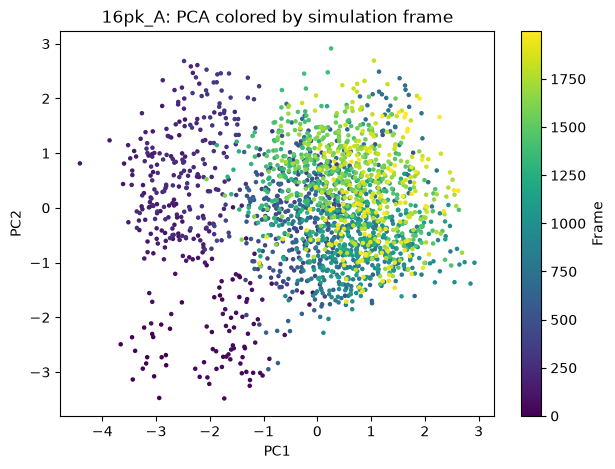

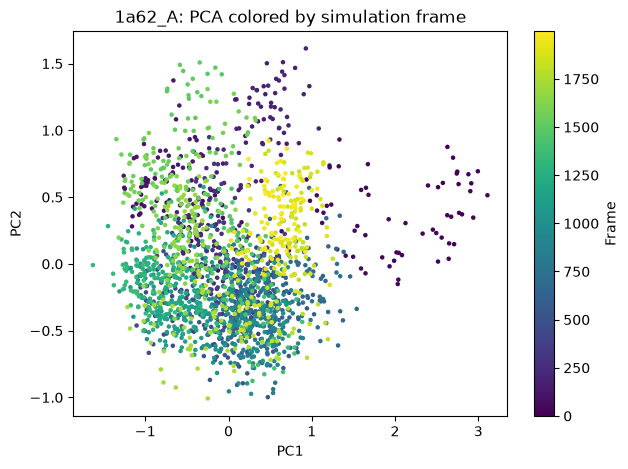

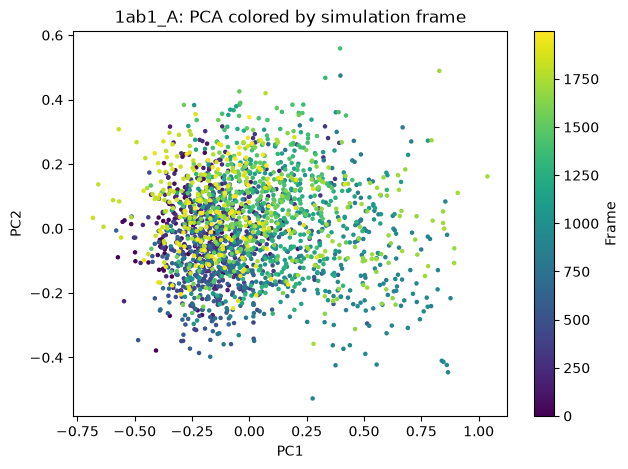

In [7]:
for protein in proteins:
    pca = data[protein]["pca"]

    frames = np.arange(M)

    plt.figure(figsize=(7, 5))
    plt.scatter(
        pca[:, 0],
        pca[:, 1],
        c=frames,
        s=5
    )

    plt.xlabel("PC1")
    plt.ylabel("PC2")
    plt.title(f"{protein}: PCA colored by simulation frame")
    plt.colorbar(label="Frame")
    plt.show()

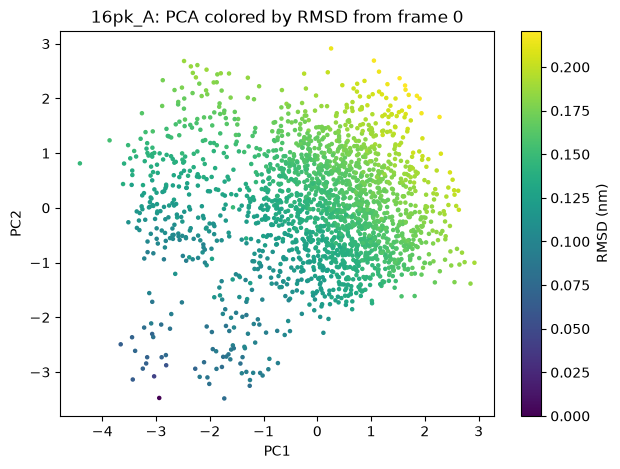

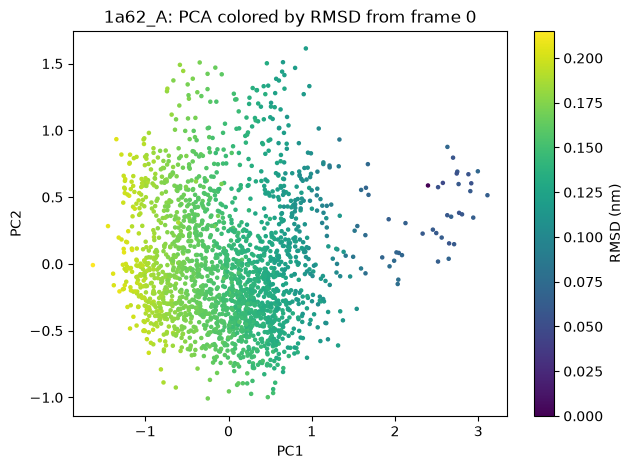

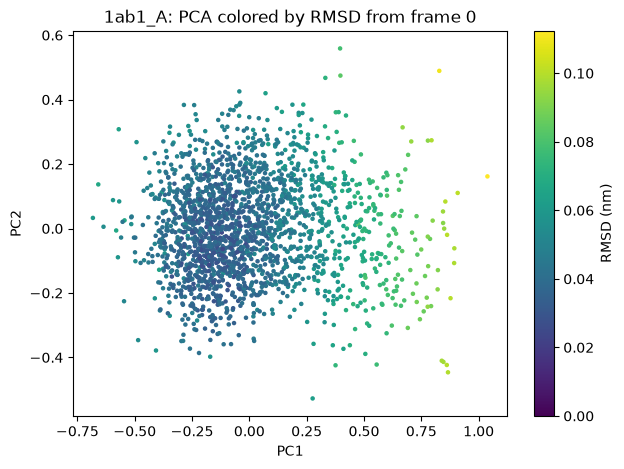

In [8]:
for protein in proteins:
    pca = data[protein]["pca"]
    rmsd = data[protein]["rmsd"]

    plt.figure(figsize=(7, 5))

    plt.scatter(
        pca[:, 0],
        pca[:, 1],
        c=rmsd,
        s=5
    )

    plt.xlabel("PC1")
    plt.ylabel("PC2")
    plt.title(f"{protein}: PCA colored by RMSD from frame 0")
    plt.colorbar(label="RMSD (nm)")
    plt.show()

In [9]:
from sklearn.manifold import TSNE

for protein in proteins:
    X = data[protein]["X"]

    tsne = TSNE(
        n_components=2,
        perplexity=30,
        random_state=42
    )

    X_tsne = tsne.fit_transform(X)

    data[protein]["tsne"] = X_tsne

    print(protein, X_tsne.shape)

16pk_A (2000, 2)
1a62_A (2000, 2)
1ab1_A (2000, 2)


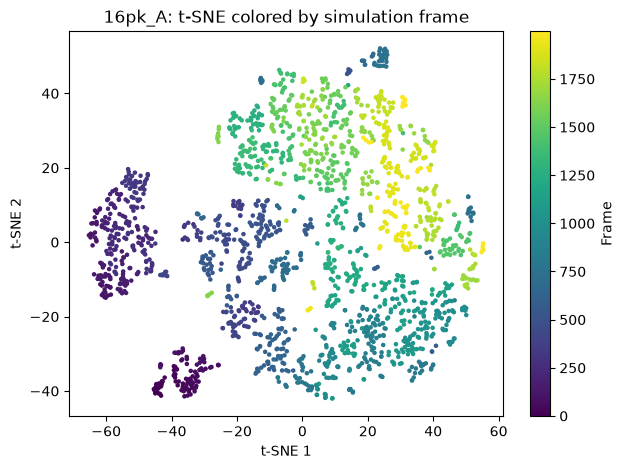

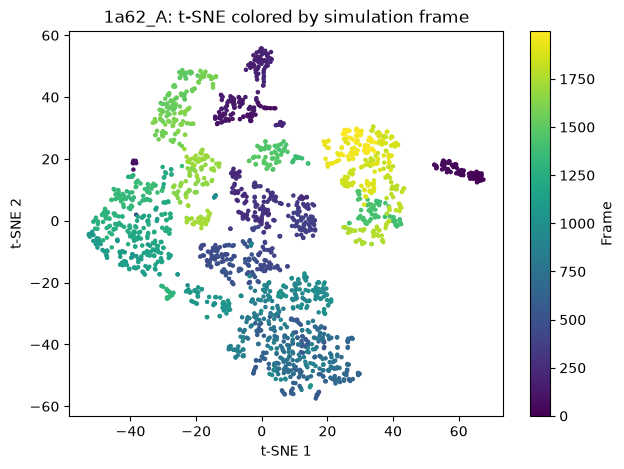

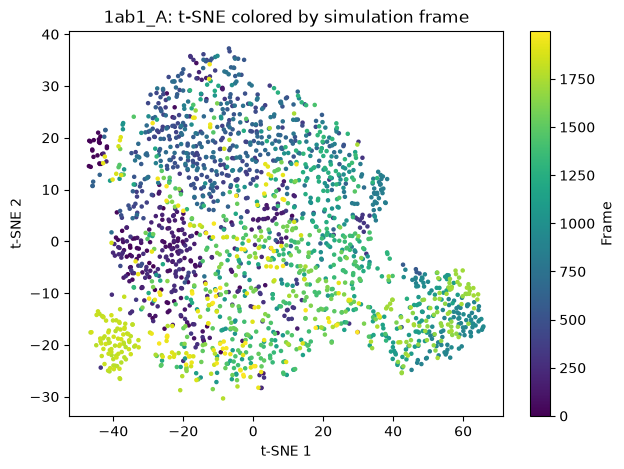

In [10]:
for protein in proteins:
    tsne = data[protein]["tsne"]

    frames = np.arange(M)

    plt.figure(figsize=(7, 5))

    plt.scatter(
        tsne[:, 0],
        tsne[:, 1],
        c=frames,
        s=5
    )

    plt.xlabel("t-SNE 1")
    plt.ylabel("t-SNE 2")
    plt.title(f"{protein}: t-SNE colored by simulation frame")
    plt.colorbar(label="Frame")

    plt.show()

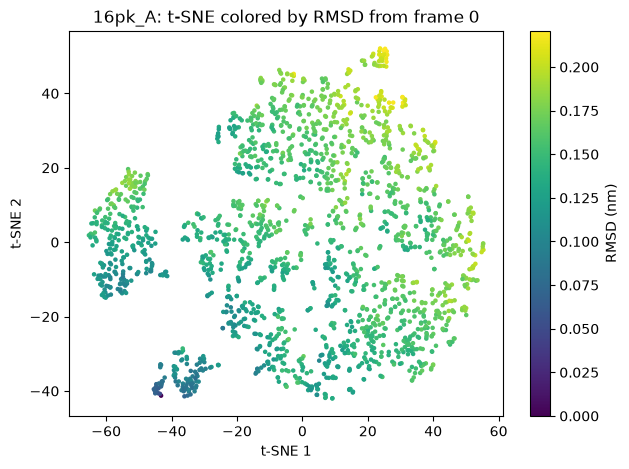

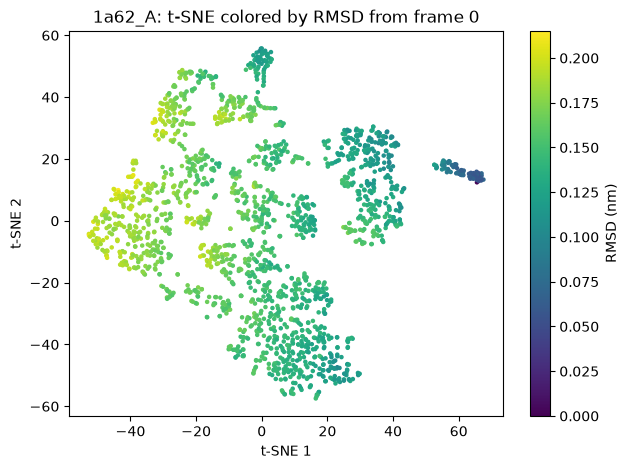

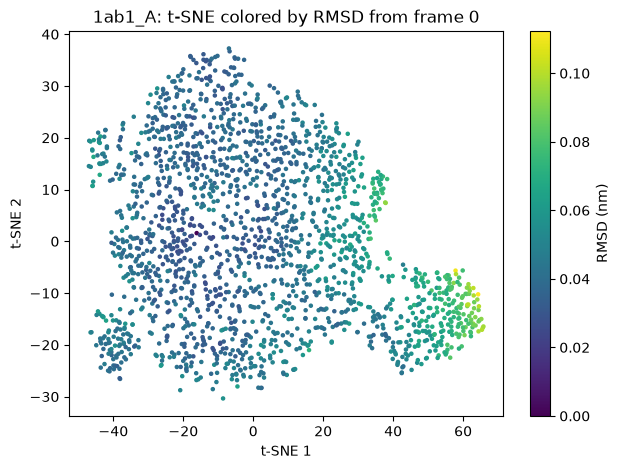

In [11]:
for protein in proteins:
    tsne = data[protein]["tsne"]
    rmsd = data[protein]["rmsd"]

    plt.figure(figsize=(7, 5))

    plt.scatter(
        tsne[:, 0],
        tsne[:, 1],
        c=rmsd,
        s=5
    )

    plt.xlabel("t-SNE 1")
    plt.ylabel("t-SNE 2")
    plt.title(f"{protein}: t-SNE colored by RMSD from frame 0")
    plt.colorbar(label="RMSD (nm)")

    plt.show()

In [12]:
# saving results to avoid rerunning t-sne
for protein in proteins:
    np.savez(
        f"{protein}_analysis.npz",
        rmsd=data[protein]["rmsd"],
        pca=data[protein]["pca"],
        tsne=data[protein]["tsne"]
    )

In [13]:
for protein in proteins:
    pca_var = data[protein]["pca_model"].explained_variance_ratio_

    print(
        protein,
        "| frames:", M,
        "| RMSD max:", round(float(data[protein]["rmsd"].max()), 4), "nm",
        "| PC1:", round(float(pca_var[0] * 100), 2), "%",
        "| PC2:", round(float(pca_var[1] * 100), 2), "%",
        "| PC1+PC2:", round(float(pca_var[:2].sum() * 100), 2), "%"
    )

16pk_A | frames: 2000 | RMSD max: 0.2207 nm | PC1: 37.69 % | PC2: 22.5 % | PC1+PC2: 60.19 %
1a62_A | frames: 2000 | RMSD max: 0.2151 nm | PC1: 32.75 % | PC2: 14.92 % | PC1+PC2: 47.67 %
1ab1_A | frames: 2000 | RMSD max: 0.1123 nm | PC1: 36.94 % | PC2: 11.28 % | PC1+PC2: 48.22 %


# construct graph

In [15]:
protein = "16pk_A"

traj = data[protein]["traj"]

# Take one frame
frame = traj[0]

# Calculate all pairwise C-alpha distances
distances = md.compute_distances(
    frame,
    [(i, j) for i in range(frame.n_atoms)
             for j in range(i + 1, frame.n_atoms)]
)

# Threshold: 4.5 Angstrom = 0.45 nm
threshold = 0.45

# Create adjacency matrix
N = frame.n_atoms
adjacency = np.zeros((N, N), dtype=int)

pairs = [
    (i, j)
    for i in range(N)
    for j in range(i + 1, N)
]

for (i, j), distance in zip(pairs, distances[0]):
    if distance < threshold:
        adjacency[i, j] = 1
        adjacency[j, i] = 1

print("Number of nodes:", N)
print("Number of edges:", adjacency.sum() // 2)
print("Adjacency matrix shape:", adjacency.shape)

Number of nodes: 415
Number of edges: 441
Adjacency matrix shape: (415, 415)


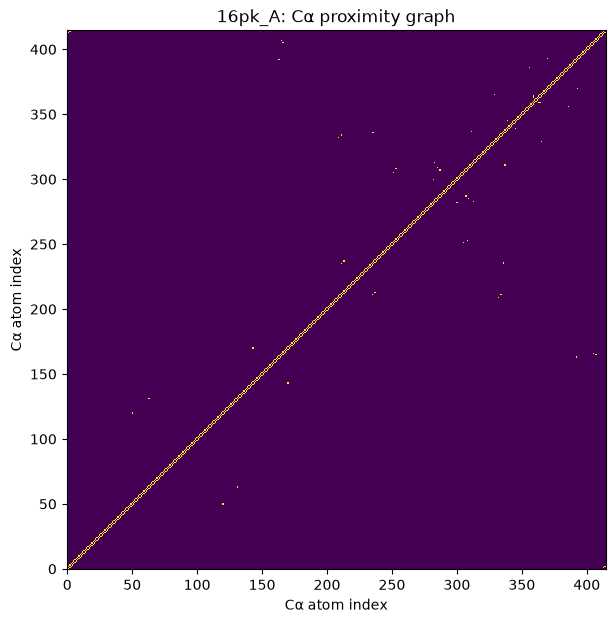

In [16]:
plt.figure(figsize=(7, 7))

plt.imshow(
    adjacency,
    origin="lower",
    interpolation="nearest"
)

plt.xlabel("Cα atom index")
plt.ylabel("Cα atom index")
plt.title(f"{protein}: Cα proximity graph")

plt.show()

In [17]:
frames_to_check = [0, 500, 1000, 1500, 1999]

In [18]:
def contact_map(traj, frame_index, threshold_nm=0.45):

    frame = traj[frame_index]

    N = frame.n_atoms

    pairs = [
        (i, j)
        for i in range(N)
        for j in range(i + 1, N)
    ]

    distances = md.compute_distances(frame, pairs)[0]

    adjacency = np.zeros((N, N), dtype=int)

    for (i, j), distance in zip(pairs, distances):
        if distance < threshold_nm:
            adjacency[i, j] = 1
            adjacency[j, i] = 1

    return adjacency

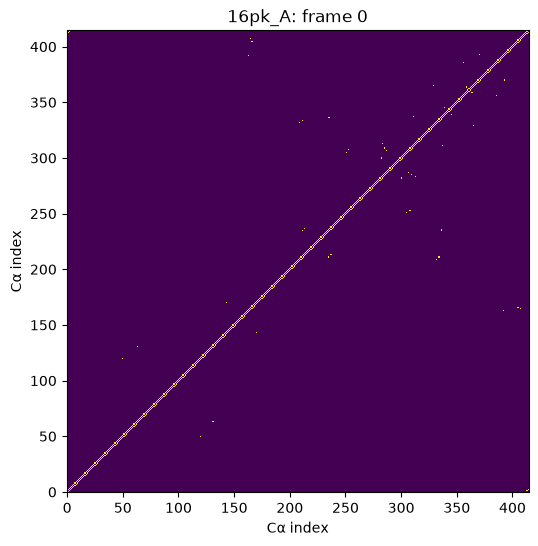

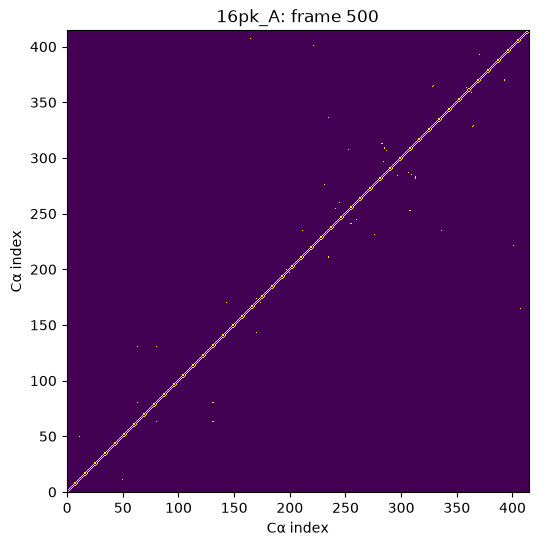

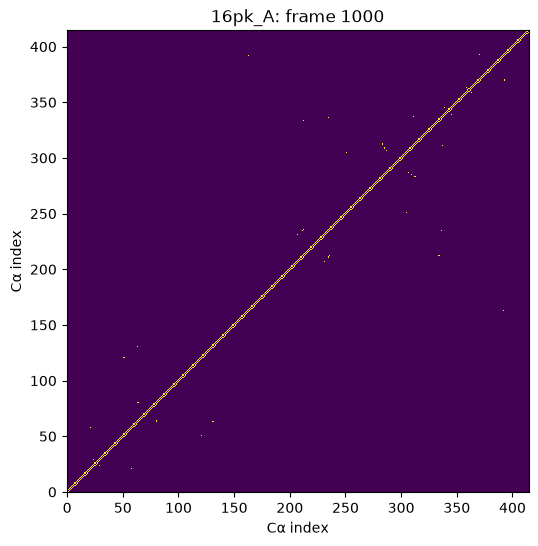

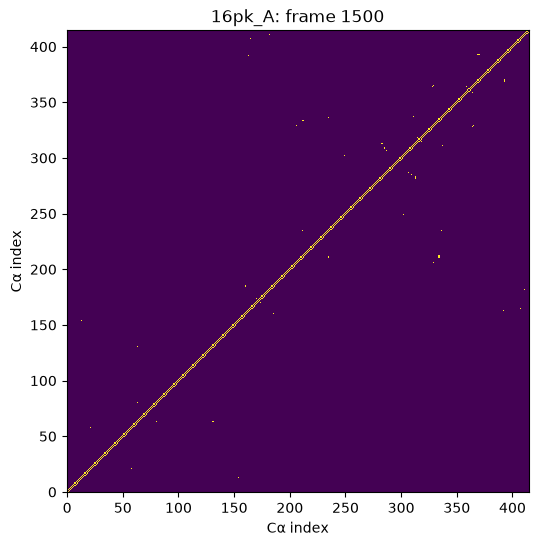

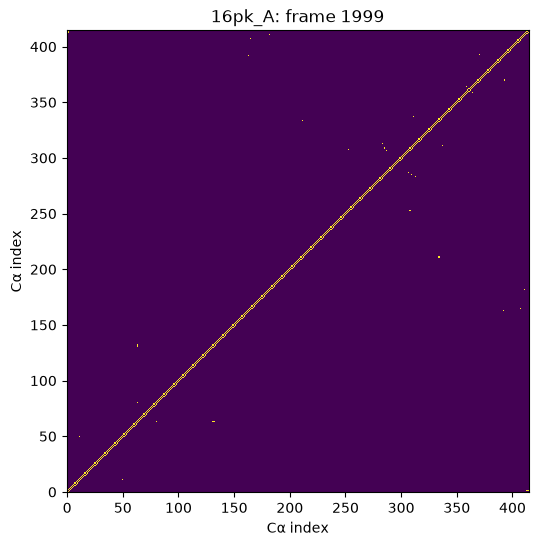

In [19]:
for frame_index in [0, 500, 1000, 1500, 1999]:

    adjacency = contact_map(
        traj,
        frame_index
    )

    plt.figure(figsize=(6, 6))

    plt.imshow(
        adjacency,
        origin="lower",
        interpolation="nearest"
    )

    plt.xlabel("Cα index")
    plt.ylabel("Cα index")
    plt.title(f"{protein}: frame {frame_index}")

    plt.show()

In [20]:
protein = "16pk_A"
traj = data[protein]["traj"][:M]

N = traj.n_atoms

upper_i, upper_j = np.triu_indices(N, k=1)

print("Number of possible edges:", len(upper_i))

Number of possible edges: 85905


In [21]:
network_data = {}

for protein in proteins:

    traj = data[protein]["traj"][:M]
    N = traj.n_atoms

    upper_i, upper_j = np.triu_indices(N, k=1)

    X_network = []

    for frame_index in range(M):

        frame = traj[frame_index]

        pairs = np.column_stack((upper_i, upper_j))

        distances = md.compute_distances(
            frame,
            pairs
        )[0]

        contacts = (distances < 0.45).astype(np.float32)

        X_network.append(contacts)

    X_network = np.array(X_network)

    network_data[protein] = X_network

    print(
        protein,
        "network feature matrix:",
        X_network.shape
    )

16pk_A network feature matrix: (2000, 85905)
1a62_A network feature matrix: (2000, 8385)
1ab1_A network feature matrix: (2000, 1035)


In [23]:
network_pca = {}

for protein in proteins:

    X_network = network_data[protein]

    pca_network = PCA(n_components=2)

    projection = pca_network.fit_transform(X_network)

    network_pca[protein] = projection

    print(
        protein,
        "network PCA:",
        projection.shape
    )

    print(
        "Explained variance:",
        pca_network.explained_variance_ratio_
    )

16pk_A network PCA: (2000, 2)
Explained variance: [0.03753833 0.03422831]
1a62_A network PCA: (2000, 2)
Explained variance: [0.09653617 0.08507113]
1ab1_A network PCA: (2000, 2)
Explained variance: [0.36684775 0.32157144]


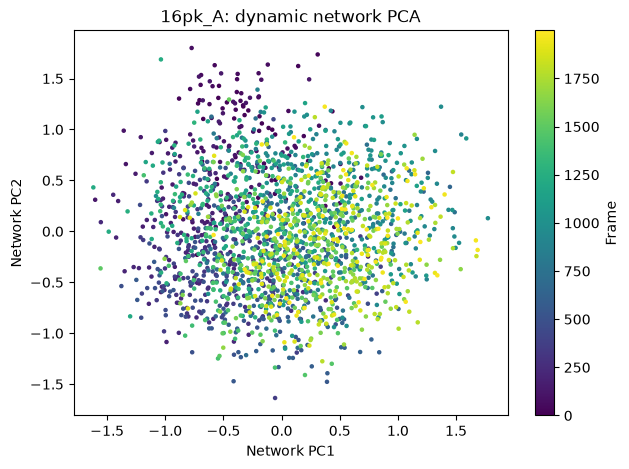

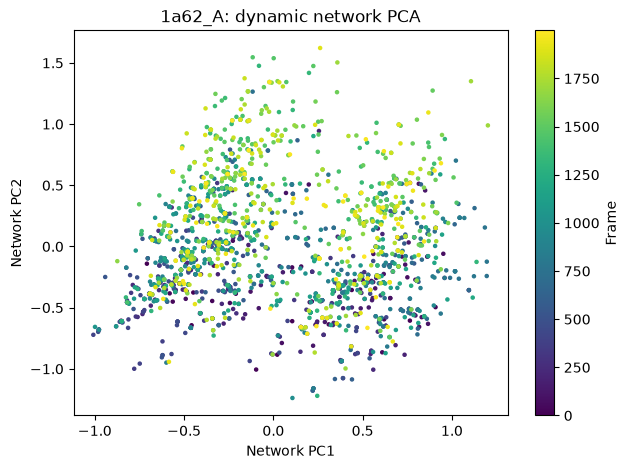

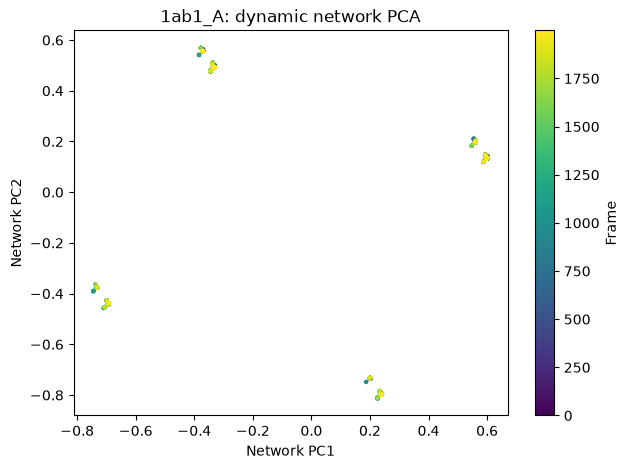

In [24]:
for protein in proteins:

    projection = network_pca[protein]

    frames = np.arange(M)

    plt.figure(figsize=(7, 5))

    plt.scatter(
        projection[:, 0],
        projection[:, 1],
        c=frames,
        s=5
    )

    plt.xlabel("Network PC1")
    plt.ylabel("Network PC2")
    plt.title(
        f"{protein}: dynamic network PCA"
    )

    plt.colorbar(label="Frame")

    plt.show()

# dynamic network

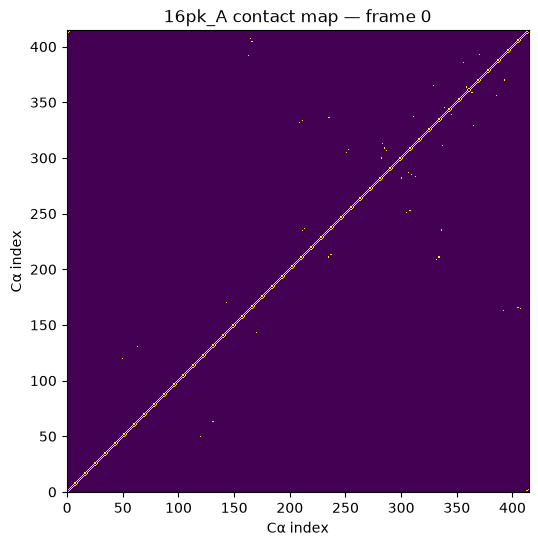

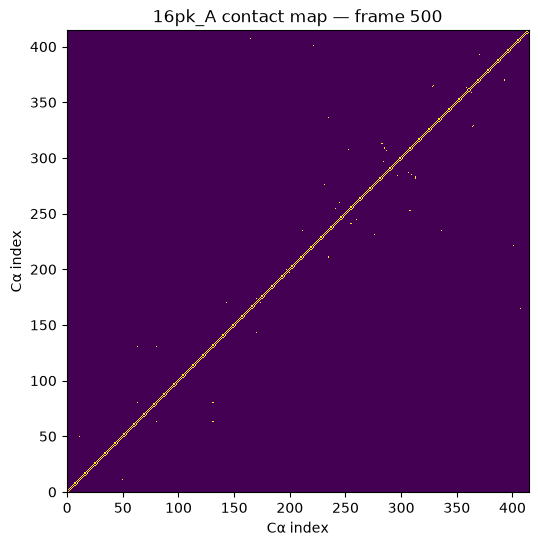

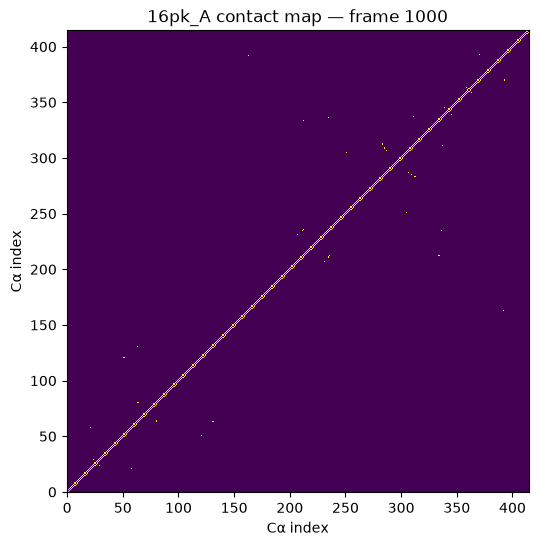

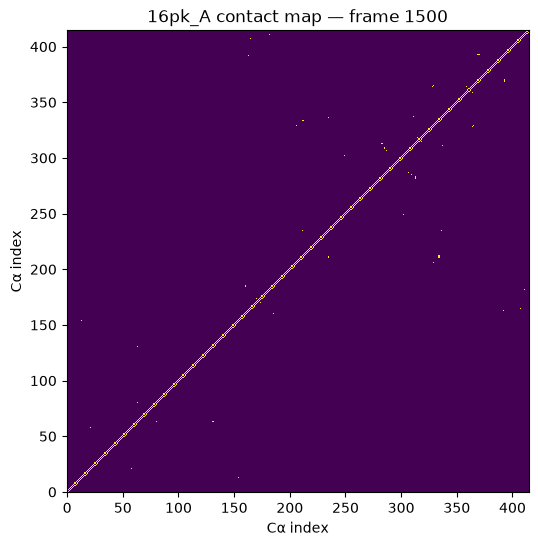

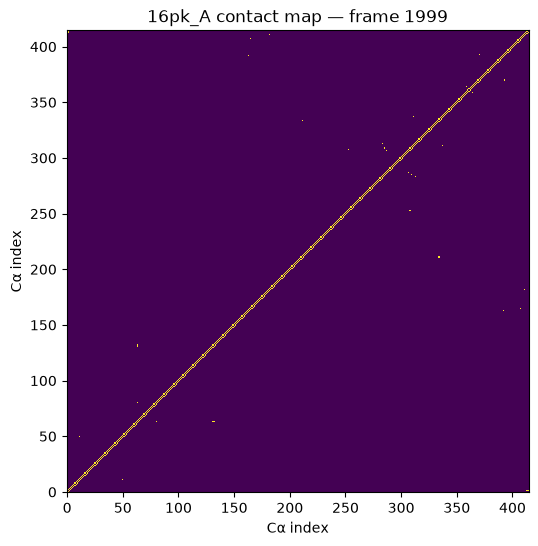

In [25]:
frames_to_check = [0, 500, 1000, 1500, 1999]

for frame_index in frames_to_check:

    adjacency = contact_map(
        data["16pk_A"]["traj"],
        frame_index
    )

    plt.figure(figsize=(6, 6))

    plt.imshow(
        adjacency,
        origin="lower",
        interpolation="nearest"
    )

    plt.xlabel("Cα index")
    plt.ylabel("Cα index")
    plt.title(f"16pk_A contact map — frame {frame_index}")

    plt.show()

In [26]:
network_data = {}

for protein in proteins:

    traj = data[protein]["traj"][:M]
    N = traj.n_atoms

    # Unique pairs of C-alpha atoms
    upper_i, upper_j = np.triu_indices(N, k=1)
    pairs = np.column_stack((upper_i, upper_j))

    network_features = []

    for frame_index in range(M):

        distances = md.compute_distances(
            traj[frame_index],
            pairs
        )[0]

        contacts = (distances < 0.45).astype(np.float32)

        network_features.append(contacts)

    network_features = np.array(network_features)

    network_data[protein] = network_features

    print(
        protein,
        "shape:",
        network_features.shape
    )

16pk_A shape: (2000, 85905)
1a62_A shape: (2000, 8385)
1ab1_A shape: (2000, 1035)


In [27]:
network_pca = {}
network_pca_models = {}

for protein in proteins:

    X_network = network_data[protein]

    pca = PCA(n_components=2)

    projection = pca.fit_transform(X_network)

    network_pca[protein] = projection
    network_pca_models[protein] = pca

    print(
        protein,
        "projection shape:",
        projection.shape
    )

    print(
        "Explained variance:",
        pca.explained_variance_ratio_
    )

16pk_A projection shape: (2000, 2)
Explained variance: [0.03753534 0.03427812]
1a62_A projection shape: (2000, 2)
Explained variance: [0.09653619 0.08507124]
1ab1_A projection shape: (2000, 2)
Explained variance: [0.3668497 0.3215702]


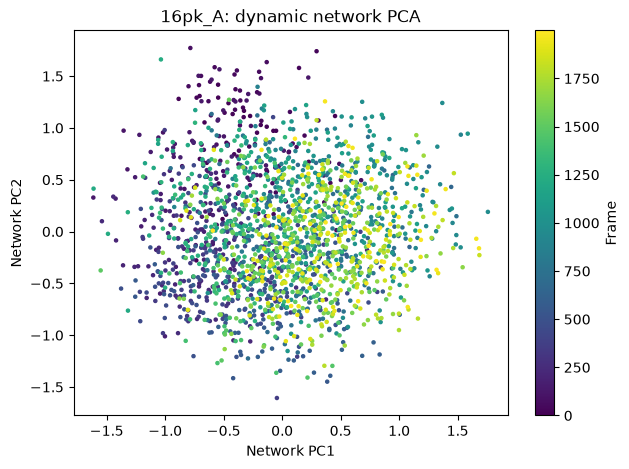

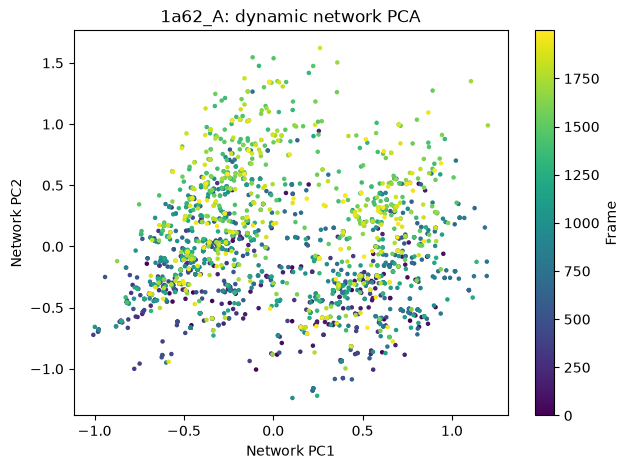

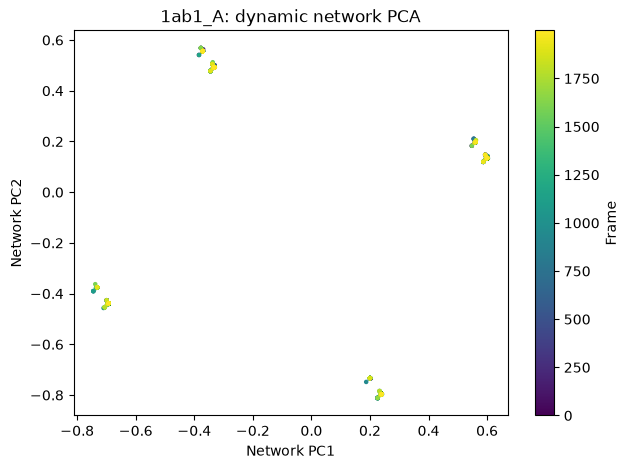

In [28]:
for protein in proteins:

    projection = network_pca[protein]

    frames = np.arange(M)

    plt.figure(figsize=(7, 5))

    plt.scatter(
        projection[:, 0],
        projection[:, 1],
        c=frames,
        s=5
    )

    plt.xlabel("Network PC1")
    plt.ylabel("Network PC2")
    plt.title(
        f"{protein}: dynamic network PCA"
    )

    plt.colorbar(label="Frame")

    plt.show()

In [29]:
for protein in proteins:
    np.savez(
        f"{protein}_network_analysis.npz",
        network_pca=network_pca[protein],
        explained_variance=network_pca_models[protein].explained_variance_ratio_
    )

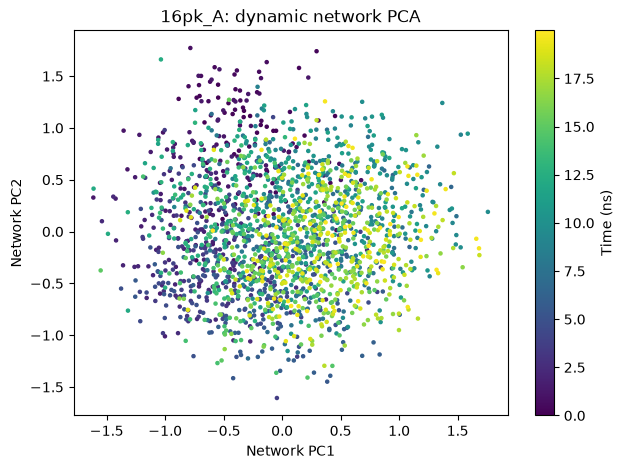

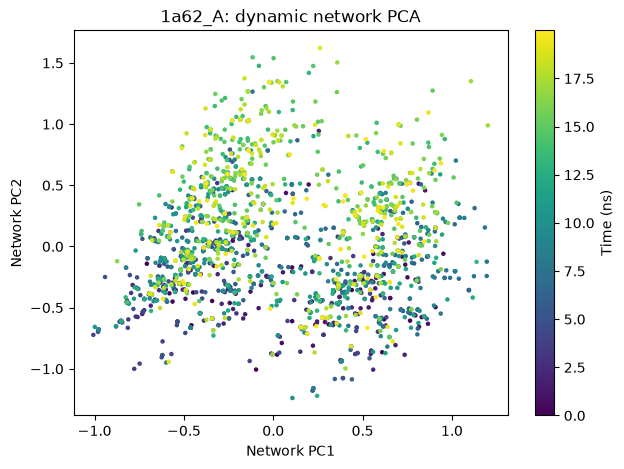

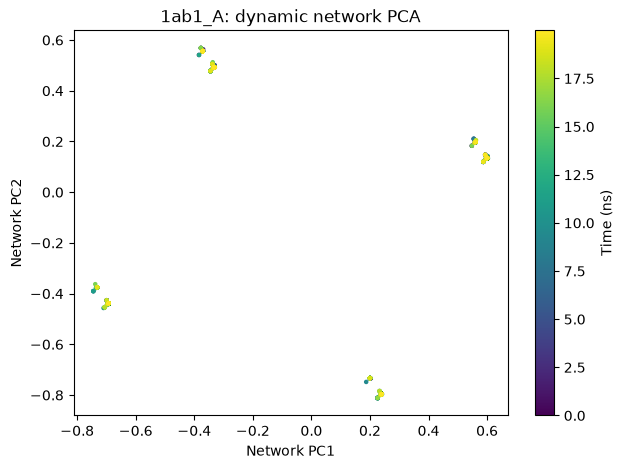

In [30]:
for protein in proteins:
    projection = network_pca[protein]

    time_ns = data[protein]["traj"].time[:M] / 1000

    plt.figure(figsize=(7, 5))

    plt.scatter(
        projection[:, 0],
        projection[:, 1],
        c=time_ns,
        s=5
    )

    plt.xlabel("Network PC1")
    plt.ylabel("Network PC2")
    plt.title(f"{protein}: dynamic network PCA")
    plt.colorbar(label="Time (ns)")

    plt.show()

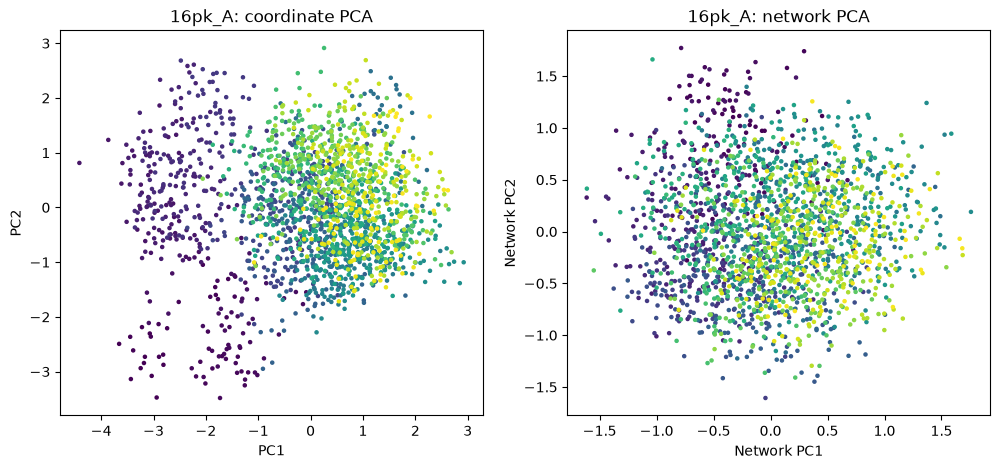

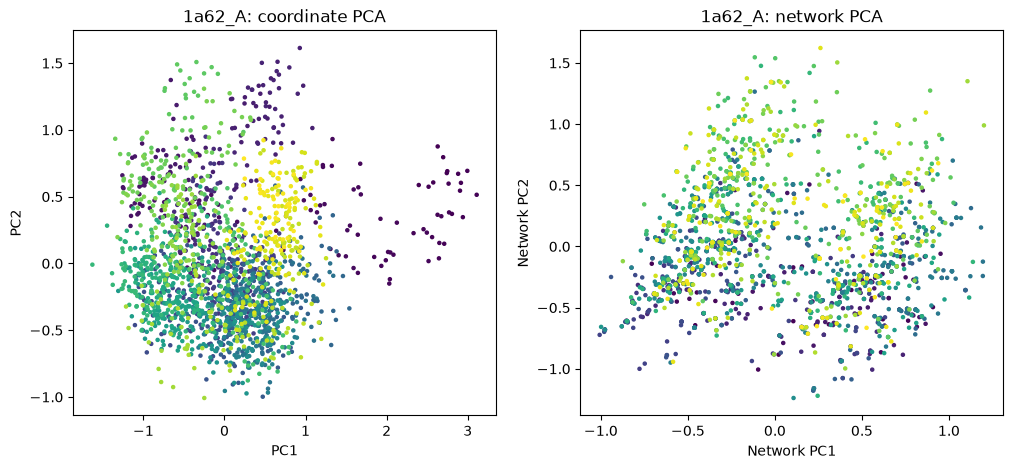

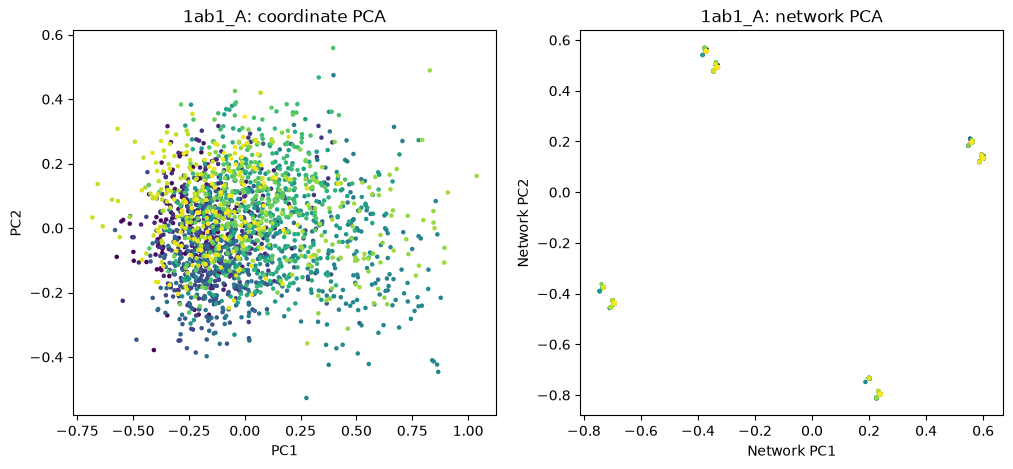

In [31]:
for protein in proteins:

    plt.figure(figsize=(12, 5))

    # Coordinate PCA
    plt.subplot(1, 2, 1)

    plt.scatter(
        data[protein]["pca"][:, 0],
        data[protein]["pca"][:, 1],
        c=np.arange(M),
        s=5
    )

    plt.xlabel("PC1")
    plt.ylabel("PC2")
    plt.title(f"{protein}: coordinate PCA")

    # Network PCA
    plt.subplot(1, 2, 2)

    plt.scatter(
        network_pca[protein][:, 0],
        network_pca[protein][:, 1],
        c=np.arange(M),
        s=5
    )

    plt.xlabel("Network PC1")
    plt.ylabel("Network PC2")
    plt.title(f"{protein}: network PCA")

    plt.show()

In [32]:
for protein in proteins:
    ev = network_pca_models[protein].explained_variance_ratio_

    print(
        protein,
        "PC1:",
        round(ev[0] * 100, 2),
        "%",
        "PC2:",
        round(ev[1] * 100, 2),
        "%",
        "PC1+PC2:",
        round(ev[:2].sum() * 100, 2),
        "%"
    )

16pk_A PC1: 3.75 % PC2: 3.43 % PC1+PC2: 7.18 %
1a62_A PC1: 9.65 % PC2: 8.51 % PC1+PC2: 18.16 %
1ab1_A PC1: 36.68 % PC2: 32.16 % PC1+PC2: 68.84 %


substantial difference: 
- 16pk_A: 60.2% --> 7.2%. this means while the Cartesian coordinates have fairly strong low-dimensional structure, the contact network changes in a much more distributed/high-dimensional way. in other words, the protein's movements can involve coordinate changes without necessarily producing a small number of dominant changes in its contact network.
- 1a62_A: 47.6% --> 18.2%. same general trend.
- 1ab1_A: 48.2% --> 68.8%. the network representation is actually more strongly low-dimensional than the Cartesian representation. suggests that the changes in its contact network may be dominated by a relatively small number of patterns.